# Understanding How Genetic Algorithm Settings Affect Performance

## Objective: 

Investigate how two important genetic algorithm settings influence the quality and consistency of the solutions:

1. Population size.
2. Mutation probability.

We will use five configurations.
Experiment | Population size | Mutation probability
| :--- | ---: | ---: |
Small population | 20 | 0.15
Baseline | 40 | 0.15
Large population | 80 | 0.15
Low mutation | 40 | 0.05
High mutation | 40 | 0.30

This design allows us to isolate the effects of each setting.

**Population experiment:** Compare 20, 40 and 80 while keeping mutation probability at 0.15.

**Mutation experiment:** Compare 0.05, 0.15 and 0.30 while keeping population size at 40.

Everything else will remain unchanged.

We will also use five independent random seeds for each configuration. This gives us 25 total GA runs.

## Prepare the experiment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
rng = np.random.default_rng(42)

In [3]:
def damped_signal(t, A, alpha, f):

    signal = (
        A
        * np.exp(-alpha * t)
        * np.sin(2 * np.pi * f * t)
    )

    return signal

In [4]:
# True parameters used to generate the signal
true_parameters = np.array([1.5, 0.15, 0.5])

# Generate measurement time points
time = np.linspace(0, 20, 400)

# Measurement noise level
noise_std = 0.05

# Generate the ideal signal
true_signal = damped_signal(
    time,
    *true_parameters
)

# Add random measurement noise
observed_signal = (
    true_signal
    + rng.normal(
        loc=0.0,
        scale=noise_std,
        size=len(time)
    )
)

In [5]:
def objective_function(
    candidate_parameters,
    time,
    observed_signal
):

    A, alpha, f = candidate_parameters

    predicted_signal = damped_signal(
        time,
        A,
        alpha,
        f
    )

    errors = observed_signal - predicted_signal

    mse = np.mean(errors ** 2)

    return mse

In [6]:
# Parameter boundaries

lower_bounds = np.array([
    0.5,    # Minimum amplitude
    0.01,   # Minimum damping coefficient
    0.20    # Minimum frequency
])

upper_bounds = np.array([
    2.5,    # Maximum amplitude
    0.50,   # Maximum damping coefficient
    0.80    # Maximum frequency
])


# Genetic algorithm settings
number_generations = 100

# Selection settings
tournament_size = 3

# Crossover settings
crossover_probability = 0.9

# Mutation settings
mutation_scales = np.array([
    0.10,   # Amplitude mutation scale
    0.025,  # Damping mutation scale
    0.025   # Frequency mutation scale
])

# Elitism
elitism_count = 2

In [11]:
def tournament_selection(
    population,
    objective_values,
    tournament_size,
    rng
):

    competitor_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    winner_index = competitor_indices[
        np.argmin(
            objective_values[competitor_indices]
        )
    ]

    return population[winner_index].copy()

In [12]:
def arithmetic_crossover(parent1, parent2, rng):

    alpha = rng.random(size=parent1.shape)

    child = (
        alpha * parent1
        + (1 - alpha) * parent2
    )

    return child

In [13]:
def mutate(
    child,
    mutation_probability,
    mutation_scales,
    lower_bounds,
    upper_bounds,
    rng
):

    mutated_child = child.copy()

    mutation_mask = (
        rng.random(size=mutated_child.shape)
        < mutation_probability
    )

    mutation_values = rng.normal(
        loc=0.0,
        scale=mutation_scales,
        size=mutated_child.shape
    )

    mutated_child += mutation_mask * mutation_values

    mutated_child = np.clip(
        mutated_child,
        lower_bounds,
        upper_bounds
    )

    return mutated_child

In [15]:
print("Number of observations:", len(time))

print("True parameters:", true_parameters)

print("Observed signal shape:", observed_signal.shape)

Number of observations: 400
True parameters: [1.5  0.15 0.5 ]
Observed signal shape: (400,)


## 1. Configurable genetic algorithm

Create a reusable GA function that accepts:

- A random seed.
- Population size.
- Mutation probability.

All other algorithm settings remain fixed.

This will allow us to compare different configurations
under controlled conditions.

In [16]:
def run_genetic_algorithm(
    seed,
    population_size,
    mutation_probability
):

    # Create a random-number generator
    rng = np.random.default_rng(seed)

    # Generate the initial population
    population = rng.uniform(
        low=lower_bounds,
        high=upper_bounds,
        size=(population_size, 3)
    )

    # Store performance history
    history = {
        "best_mse": [],
        "mean_mse": [],
        "best_parameters": []
    }

    # Evolutionary process
    for generation in range(number_generations + 1):

        # Evaluate the population
        objective_values = np.array([
            objective_function(
                individual,
                time,
                observed_signal
            )
            for individual in population
        ])

        # Identify the best candidate
        best_index = np.argmin(objective_values)

        best_candidate = population[best_index].copy()

        best_value = objective_values[best_index]

        # Record results
        history["best_mse"].append(best_value)

        history["mean_mse"].append(
            np.mean(objective_values)
        )

        history["best_parameters"].append(
            best_candidate.copy()
        )

        # Stop after recording the final generation
        if generation == number_generations:
            break

        # Prepare the next generation
        next_population = []

        # Preserve elite candidates
        elite_indices = np.argsort(objective_values)[
            :elitism_count
        ]

        for index in elite_indices:

            next_population.append(
                population[index].copy()
            )

        # Generate offspring
        while len(next_population) < population_size:

            # Select parents
            parent1 = tournament_selection(
                population,
                objective_values,
                tournament_size,
                rng
            )

            parent2 = tournament_selection(
                population,
                objective_values,
                tournament_size,
                rng
            )

            # Apply crossover
            if rng.random() < crossover_probability:

                child = arithmetic_crossover(
                    parent1,
                    parent2,
                    rng
                )

            else:

                child = parent1.copy()

            # Apply mutation
            child = mutate(
                child,
                mutation_probability,
                mutation_scales,
                lower_bounds,
                upper_bounds,
                rng
            )

            next_population.append(child)

        # Replace current population
        population = np.array(next_population)

    return history

## 2. Experimental configurations

Define five GA configurations.

Three configurations will investigate population size,
while the other three will investigate mutation probability.

The baseline configuration is shared by both comparisons.

In [17]:
configurations = [

    {
        "name": "Small population",
        "population_size": 20,
        "mutation_probability": 0.15
    },

    {
        "name": "Baseline",
        "population_size": 40,
        "mutation_probability": 0.15
    },

    {
        "name": "Large population",
        "population_size": 80,
        "mutation_probability": 0.15
    },

    {
        "name": "Low mutation",
        "population_size": 40,
        "mutation_probability": 0.05
    },

    {
        "name": "High mutation",
        "population_size": 40,
        "mutation_probability": 0.30
    }

]

In [18]:
configuration_table = pd.DataFrame(configurations)

display(configuration_table)

,name,population_size,mutation_probability
0,Small population,20,0.15
1,Baseline,40,0.15
2,Large population,80,0.15
3,Low mutation,40,0.05
4,High mutation,40,0.30


In [19]:
seeds = [11, 23, 37, 52, 68]

## 3. Repeated experimental runs

Execute each configuration five times using different
random seeds.

For each run, record:

- Estimated amplitude.
- Estimated damping coefficient.
- Estimated frequency.
- Best MSE.
- Final population mean MSE.

Store the convergence history for later comparison.

In [20]:
# Store all experimental results
experiment_results = []

# Store convergence histories
experiment_histories = {}

# Run each configuration
for config in configurations:

    config_name = config["name"]

    print(f"Running configuration: {config_name}")

    for seed in seeds:

        # Execute the genetic algorithm
        history = run_genetic_algorithm(
            seed=seed,
            population_size=config["population_size"],
            mutation_probability=config["mutation_probability"]
        )

        # Identify the best solution
        best_index = np.argmin(history["best_mse"])

        estimated_parameters = np.array(
            history["best_parameters"][best_index]
        )

        best_mse = history["best_mse"][best_index]

        final_mean_mse = history["mean_mse"][-1]

        # Store the convergence history
        experiment_histories[(config_name, seed)] = history

        # Store the numerical results
        experiment_results.append({

            "Configuration": config_name,

            "Seed": seed,

            "Population Size": config["population_size"],

            "Mutation Probability": config["mutation_probability"],

            "Estimated A": estimated_parameters[0],

            "Estimated Alpha": estimated_parameters[1],

            "Estimated Frequency": estimated_parameters[2],

            "Best MSE": best_mse,

            "Final Mean MSE": final_mean_mse

        })

print("\nAll experiments completed.")

Running configuration: Small population
Running configuration: Baseline
Running configuration: Large population
Running configuration: Low mutation
Running configuration: High mutation

All experiments completed.


In [21]:
experiment_table = pd.DataFrame(experiment_results)

display(experiment_table)

,Configuration,Seed,Population Size,Mutation Probability,Estimated A,Estimated Alpha,Estimated Frequency,Best MSE,Final Mean MSE
0,Small population,11,20,0.15,1.500639,0.151101,0.500007,0.002259,0.025806
1,Small population,23,20,0.15,1.499432,0.150824,0.500222,0.002265,0.009004
2,Small population,37,20,0.15,1.498252,0.150681,0.499704,0.002274,0.016124
3,Small population,52,20,0.15,1.500064,0.150941,0.500001,0.002259,0.007256
4,Small population,68,20,0.15,1.498409,0.150616,0.499991,0.002259,0.009829
5,Baseline,11,40,0.15,1.499911,0.150882,0.500023,0.002259,0.019028
6,Baseline,23,40,0.15,1.499295,0.150817,0.500022,0.002259,0.010632
7,Baseline,37,40,0.15,1.499352,0.150823,0.500022,0.002259,0.009142
8,Baseline,52,40,0.15,1.499958,0.150912,0.500027,0.002259,0.007628
9,Baseline,68,40,0.15,1.502639,0.151196,0.500020,0.002259,0.011256


## 4. Population-size comparison

Compare the small, baseline and large populations.

Evaluate how population size affects:

- Best MSE.
- Mean MSE.
- Consistency across independent runs.

In [26]:
population_results = experiment_table[
    experiment_table["Configuration"].isin([
        "Small population",
        "Baseline",
        "Large population"
    ])
]

population_summary = population_results.groupby(
    "Configuration"
).agg(

    Mean_Best_MSE=("Best MSE", "mean"),

    SD_Best_MSE=("Best MSE", "std"),

    Mean_Final_MSE=("Final Mean MSE", "mean"),

    Mean_Amplitude=("Estimated A", "mean"),

    Mean_Damping=("Estimated Alpha", "mean"),

    Mean_Frequency=("Estimated Frequency", "mean")

).reset_index()

# display(population_results)
display(population_summary)

,Configuration,Mean_Best_MSE,SD_Best_MSE,Mean_Final_MSE,Mean_Amplitude,Mean_Damping,Mean_Frequency
0,Baseline,0.002259,1.994762e-07,0.011537,1.500231,0.150926,0.500023
1,Large population,0.002259,3.213765e-08,0.009816,1.499246,0.150811,0.500021
2,Small population,0.002263,6.671378e-06,0.013604,1.499359,0.150832,0.499985


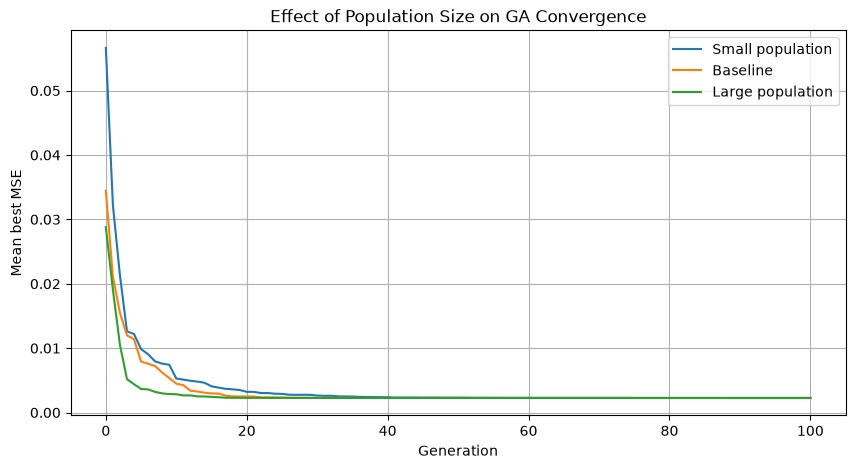

In [27]:
plt.figure(figsize=(10, 5))

population_names = [
    "Small population",
    "Baseline",
    "Large population"
]

for name in population_names:

    curves = [
        experiment_histories[(name, seed)]["best_mse"]
        for seed in seeds
    ]

    mean_curve = np.mean(curves, axis=0)

    plt.plot(
        mean_curve,
        label=name
    )

plt.xlabel("Generation")

plt.ylabel("Mean best MSE")

plt.title("Effect of Population Size on GA Convergence")

plt.legend()

plt.grid(True)

plt.show()

## 5. Mutation-probability comparison

Compare low, baseline and high mutation probabilities.

Evaluate the effect of mutation probability on:

- Best MSE.
- Mean MSE.
- Consistency across independent runs.
- Convergence behaviour.

In [28]:
mutation_results = experiment_table[
    experiment_table["Configuration"].isin([
        "Low mutation",
        "Baseline",
        "High mutation"
    ])
]

mutation_summary = mutation_results.groupby(
    "Configuration"
).agg(

    Mean_Best_MSE=("Best MSE", "mean"),

    SD_Best_MSE=("Best MSE", "std"),

    Mean_Final_MSE=("Final Mean MSE", "mean"),

    Mean_Amplitude=("Estimated A", "mean"),

    Mean_Damping=("Estimated Alpha", "mean"),

    Mean_Frequency=("Estimated Frequency", "mean")

).reset_index()

display(mutation_summary)

,Configuration,Mean_Best_MSE,SD_Best_MSE,Mean_Final_MSE,Mean_Amplitude,Mean_Damping,Mean_Frequency
0,Baseline,0.002259,1.994762e-07,0.011537,1.500231,0.150926,0.500023
1,High mutation,0.002259,2.670121e-08,0.021402,1.499225,0.150820,0.500028
2,Low mutation,0.002266,3.865859e-06,0.004627,1.508389,0.152302,0.500058


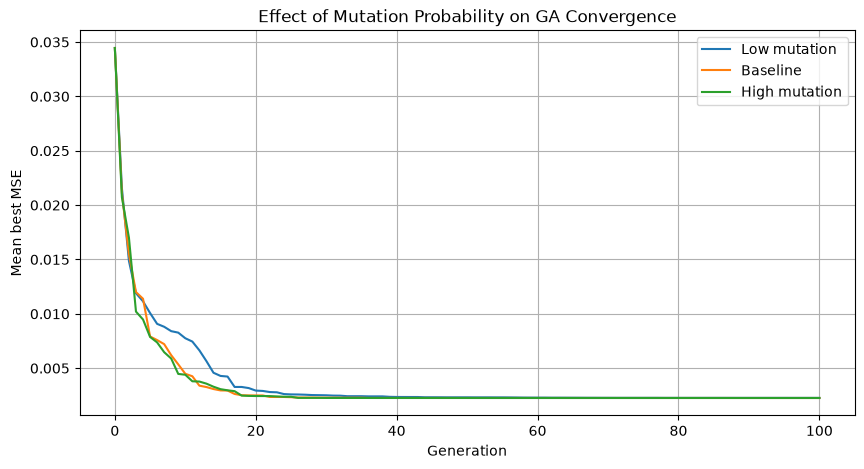

In [29]:
plt.figure(figsize=(10, 5))

mutation_names = [
    "Low mutation",
    "Baseline",
    "High mutation"
]

for name in mutation_names:

    curves = [
        experiment_histories[(name, seed)]["best_mse"]
        for seed in seeds
    ]

    mean_curve = np.mean(curves, axis=0)

    plt.plot(
        mean_curve,
        label=name
    )

plt.xlabel("Generation")

plt.ylabel("Mean best MSE")

plt.title("Effect of Mutation Probability on GA Convergence")

plt.legend()

plt.grid(True)

plt.show()

## 6. Compare all five configurations

In [30]:
overall_summary = experiment_table.groupby(
    "Configuration"
).agg(

    Mean_Best_MSE=("Best MSE", "mean"),

    SD_Best_MSE=("Best MSE", "std"),

    Mean_Final_MSE=("Final Mean MSE", "mean"),

    SD_Final_MSE=("Final Mean MSE", "std"),

    Mean_Amplitude=("Estimated A", "mean"),

    Mean_Damping=("Estimated Alpha", "mean"),

    Mean_Frequency=("Estimated Frequency", "mean")

).reset_index()

display(
    overall_summary.sort_values("Mean_Best_MSE")
)

,Configuration,Mean_Best_MSE,SD_Best_MSE,Mean_Final_MSE,SD_Final_MSE,Mean_Amplitude,Mean_Damping,Mean_Frequency
2,Large population,0.002259,3.213765e-08,0.009816,0.001977,1.499246,0.150811,0.500021
1,High mutation,0.002259,2.670121e-08,0.021402,0.009140,1.499225,0.150820,0.500028
0,Baseline,0.002259,1.994762e-07,0.011537,0.004416,1.500231,0.150926,0.500023
4,Small population,0.002263,6.671378e-06,0.013604,0.007598,1.499359,0.150832,0.499985
3,Low mutation,0.002266,3.865859e-06,0.004627,0.001834,1.508389,0.152302,0.500058


## 7. Interpret computational cost

In [38]:
computational_cost = pd.DataFrame(configurations)

computational_cost["Expected Evaluations"] = (
    computational_cost["population_size"]
    * (number_generations + 1)
)

display(
    computational_cost[
        [
            "name",
            "population_size",
            "mutation_probability",
            "Expected Evaluations"
        ]
    ]
)
# or simply:
# display(
#    computational_cost
# )

,name,population_size,mutation_probability,Expected Evaluations
0,Small population,20,0.15,2020
1,Baseline,40,0.15,4040
2,Large population,80,0.15,8080
3,Low mutation,40,0.05,4040
4,High mutation,40,0.30,4040
